# 能源与电力优化 · 两时段机组容量承诺

QuantumBridge / 工业优化 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 仅容量充裕度教学模型；未含 AC/DC 潮流、备用、爬坡、最小启停时间、储能或电网安全约束，不可作为真实电网调度指令。

## 1. 原理与计算对象

两机组容量为 2、1，两时段需求为 2、3。四比特按时段编码两台机组开关。目标为开机费用 3/2 加每次启动费用 1；初始均停机。
约束只要求可用容量至少达到需求，缺额平方罚系数 20。$C=\sum_{t,g}c_g u_{tg}+\sum startup+20\sum_t\max(0,d_t-\sum_g P_g u_{tg})^2$。

容量超过需求并不表示实际发电超额，因为本例没有建立出力决策；输出必须叫 available_capacity，而不能伪装成可直接下发的发电功率。

## 2. 实现步骤

1. 设置机组容量、时段需求、开机及启动成本。
2. 逐候选计算开关状态、容量缺口和启动次数。
3. 用完全枚举检查可行性与最优开机成本。
4. 训练原生对角 QAOA 并采样候选。
5. 解码可行承诺计划，比较目标差并保留容量约束检查。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def energy_case():
    candidates = []
    for bits in labels(4):
        x = list(map(int, bits))
        status = [x[:2], x[2:]]
        available = [2 * row[0] + row[1] for row in status]
        deficit = [
            max(0, demand - capacity) for demand, capacity in zip((2, 3), available)
        ]
        starts = sum(status[0]) + sum(
            int(status[1][i] and not status[0][i]) for i in range(2)
        )
        cost = sum(3 * row[0] + 2 * row[1] for row in status) + starts
        violation = sum(value**2 for value in deficit)
        candidates.append(
            {
                "bitstring": bits,
                "commitment_by_time": status,
                "available_capacity": available,
                "capacity_deficit": deficit,
                "startups": starts,
                "feasible": violation == 0,
                "objective": cost,
                "penalized_cost": cost + 20 * violation,
            }
        )
    return optimization_case(
        "energy",
        "industry",
        "Two-period generating-capacity commitment",
        {
            "generator_capacity": [2, 1],
            "on_cost_per_period": [3, 2],
            "startup_cost": 1,
            "demand": [2, 3],
            "initial_status": [0, 0],
            "penalty": 20,
            "scope": "capacity adequacy only; no dispatch, ramping, reserve, storage or AC power flow",
        },
        candidates,
    )


In [3]:
case = energy_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

bitstring,commitment_by_time,available_capacity,capacity_deficit,startups,feasible,objective,penalized_cost
0000,"[[0, 0], [0, 0]]","[0, 0]","[2, 3]",0,False,0,260
0001,"[[0, 0], [0, 1]]","[0, 1]","[2, 2]",1,False,3,163
0010,"[[0, 0], [1, 0]]","[0, 2]","[2, 1]",1,False,4,104
0011,"[[0, 0], [1, 1]]","[0, 3]","[2, 0]",2,False,7,87
0100,"[[0, 1], [0, 0]]","[1, 0]","[1, 3]",1,False,3,203
0101,"[[0, 1], [0, 1]]","[1, 1]","[1, 2]",1,False,5,105
0110,"[[0, 1], [1, 0]]","[1, 2]","[1, 1]",2,False,7,47
0111,"[[0, 1], [1, 1]]","[1, 3]","[1, 0]",2,False,9,29
1000,"[[1, 0], [0, 0]]","[2, 0]","[0, 3]",1,False,4,184
1001,"[[1, 0], [0, 1]]","[2, 1]","[0, 2]",2,False,7,87


improvement,expected_penalized_cost,gamma,beta
0,101.5,0,0
1,101.5,0,0.24166097
2,101.5,0,1.9332878
3,96.087054,0.78539816,1.6916268
4,85.788241,0.78539816,1.9332878
5,76.913486,0.78539816,2.1749488
6,71.889996,0.78539816,2.4166097
7,58.025159,1.5707963,2.1749488
8,49.13584,1.5707963,2.4166097
9,46.659222,2.3561945,2.1749488


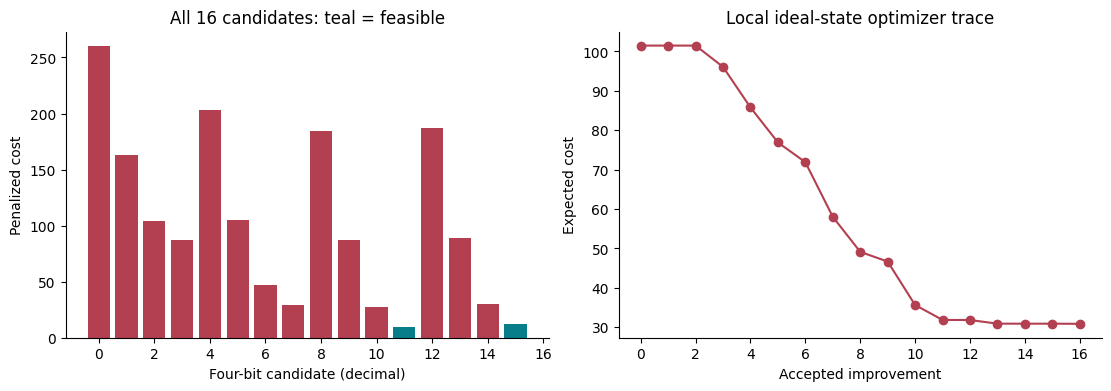

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
qaoa,4,26,1024,20261023


observable,estimate,standard_error,ideal_reference
qaoa,32.604492,1.2319951,30.859825


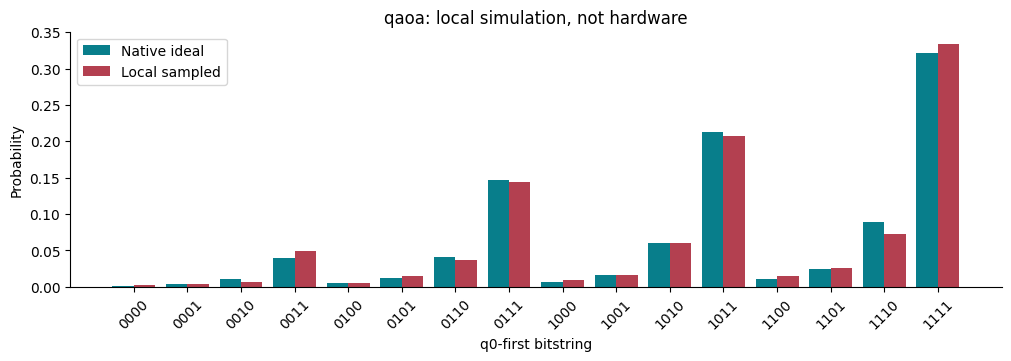

experiment,counts
qaoa,"{""1010"": 62, ""1110"": 74, ""1111"": 342, ""1000"": 9, ""0111"": 147, ""1011"": 212, ""0011"": 50, ""1001"": 16, ""0101"": 15, ""0010"": 7, ""1100"": 15, ""1101"": 26, ""0110"": 37, ""0100"": 5, ""0001"": 4, ""0000"": 3}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- qaoa ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
h q[0];
h q[1];
h q[2];
h q[3];
cx q[0],q[1];
rz(0.36799111843077503) q[1];
cx q[0],q[1];
cx q[0],q[2];
rz(-0.0061331853071795138) q[2];
cx q[0],q[2];
rz(0.57038623356770146) q[0];
cx q[1],q[3];
rz(-0.0061331853071795884) q[3];
cx q[1],q[3];
rz(0.33732519189487714) q[1];
cx q[2],q[3];
rz(0.49065482457436671) q[3];
cx q[2],q[3];
rz(1.4290321765728433) q[2];
rz(0.70531631032565245) q[3];
rz(2.2447458224277281) q[0];
u1(-2.2447458224277281) q[0];
rx(4.98321946706122) q[0];
rx(4.98321946706122) q[1];
rx(4.98321946706122) q[2];
rx(4.98321946706122) q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];



## 8. 结果解释、复做与非目标

检查 capacity_deficit 全为零后才能解释经济性。available_capacity 是可用容量，不是实际发电量；精确最优承诺成本为本模型的比较基线。

仅容量充裕度教学模型；未含 AC/DC 潮流、备用、爬坡、最小启停时间、储能或电网安全约束，不可作为真实电网调度指令。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/industry/03_energy_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 03_energy_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [Qiskit Optimization 整数与约束建模](https://qiskit-community.github.io/qiskit-optimization/tutorials/01_quadratic_program.html)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。